<a href="https://colab.research.google.com/github/x72g9hmdhf-bot/telecom-analysis/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
print("plans", plans.info())# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes
plans None


In [ ]:
print("users", users.info())# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB
users None


In [ ]:
print("usage", usage.info())# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB
usage None


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [ ]:
print(usage.isna().sum())# cantidad de nulos para usage
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64



✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos.

 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?
  En users columna city se usara el terminino sin ciudad ya que solo es el 12%
  en users la columna churn_date se se conserva: el nulo indica cliente activo y la columna sirve para medir cancelación
  en users la columna date hay que ponerla en tipo datetime
  En usage columna duration se va a usar promedio o mediana segun convenga 55% nulos
  en usage columna length se usara media o mediana segun convenga 44.7% nulos
  en usage la columna date tiene un porcentaje .1% por lo que se maneja como nulos


### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
users[['user_id','age']].describe()# explorar columnas numéricas de users

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` no es para hacer calculos pero vemos que tiene las 4000 filas
- La columna `age` presenta valores negativos los cuales nos alteran la media y promedio

In [ ]:
 usage[['id','user_id','duration','length']].describe()    # explorar columnas numéricas de usage

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`tienen los 4000 registros
- Las columnas duration y length tienen un poco de variacion entre su media y la mediana asi com valores en ceros y picos de 1490  caracteres

In [ ]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']].describe()
print(columnas_user)

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595


- La columna `city`city tiene 7 categorías, entre ellas el sentinel '?'; Bogotá es la más frecuente (808).
- La columna `plan`plan tiene 2 categorías: Básico (64.9%) y Premium (35.1%)

In [ ]:
# explorar columna categórica de usage
columnas_usage= usage[['type']].describe()
print(columnas_usage)

         type
count   40000
unique      2
top      text
freq    22092


- La columna `type` muestra los 4000 registros y no tiene valores atipicos en caracteres asi como se ve que el mensaje de texto es lo mas usado


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- en la columna de age en users hay valores negativos que revisar,
- en duration y length se debe revisar los picos    
- ¿Qué acción tomarías?  se va a revisar a detalle para saber que metodo usar

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date']=pd.to_datetime(users['reg_date'],errors='coerce')
print("veces que aparece el año",users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

veces que aparece el año 2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors='coerce')
print('año', usage['date'].dt.year.value_counts(dropna=False).sort_index())

año 2024.0    39950
NaN          50
Name: date, dtype: int64


In [ ]:
# Revisar los años presentes en `reg_date` de users
users[users['reg_date'].dt.year > 2024]

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
40,10040,Ana,Garcia,59,Medellín,2026-05-10,Basico,NaN
56,10056,Luis,Garcia,29,CDMX,2026-05-10,Basico,"1,72187E+18"
60,10060,Carlos,Torres,45,CDMX,2026-05-10,Basico,NaN
70,10070,Mariana,Gomez,50,CDMX,2026-05-10,Premium,NaN
248,10248,Sofia,Garcia,20,Medellín,2026-05-10,Premium,"1,72506E+18"
320,10320,Sofia,Garcia,74,GDL,2026-05-10,Premium,NaN
326,10326,Mariana,Torres,51,Medellín,2026-05-10,Premium,NaN
505,10505,Luis,Garcia,75,CDMX,2026-05-10,Basico,NaN
527,10527,Carlos,Torres,71,MTY,2026-05-10,Basico,NaN
646,10646,Luis,Ramirez,50,CDMX,2026-05-10,Premium,NaN


En `reg_date`,se observanvalores en age negativos asi como NaN en churn date y algunas ciudaddes con NaN y '?'

In [ ]:
# Revisar los años presentes en `date` de usage
usage[usage['date'].dt.year > 2024]
print("veces que aparece el año",usage['date'].dt.year.value_counts(dropna=False).sort_index())

veces que aparece el año 2024.0    39950
NaN          50
Name: date, dtype: int64


En `date`, no hay fechas posteriores a 2024

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) aparecen algubnas NaN y otras de años posteriores al año en estudio, las cuales hay que dejarlas fuera del caso.
  

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city']=users['city'].replace ('?',pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year>2024,'reg_date']=pd.NaT

# Verificar cambios
print("veces que aparece el año",users['reg_date'].dt.year.value_counts(dropna=False).sort_index())

veces que aparece el año 2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
(usage[['duration']].isna().groupby(usage['type']).sum())

,duration
type,
call,0
text,22076


In [ ]:
# Verificación MAR en usage (Missing At Random) para length
(usage[['length']].isna().groupby(usage['type']).sum())

,length
type,
call,17896
text,0


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Son MAR ya que lo nulos dependen directamente de type por lo cual se quedan asi como nulos

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage[['is_text','is_call','duration']].groupby(usage['user_id']).sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg=usage_agg.rename(columns={'is_text':'cant_mensajes','is_call':'cant_llamadas','duration':'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg,on='user_id',how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
user_profile[['cant_mensajes','cant_llamadas','cant_minutos_llamada']].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


In [ ]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

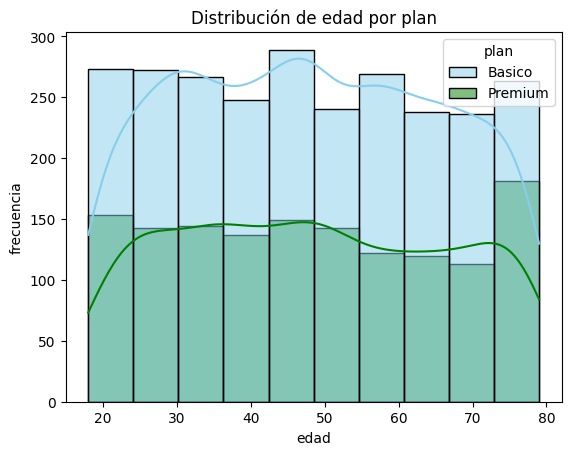

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,x='age',hue='plan',bins=10,kde=True,palette=['skyblue','green'])
plt.title('Distribución de edad por plan')
plt.xlabel('edad')
plt.ylabel('frecuencia')
plt.show()

💡Insights: La distribución de edad es similar en ambos planes (18 a 79 años); la proporción de Premium es igual en todos los grupos de edad (~35%). La distribución es aproximadamente uniforme, sin sesgo.
- Distribución la distribución se observa simetrica sin sesgos

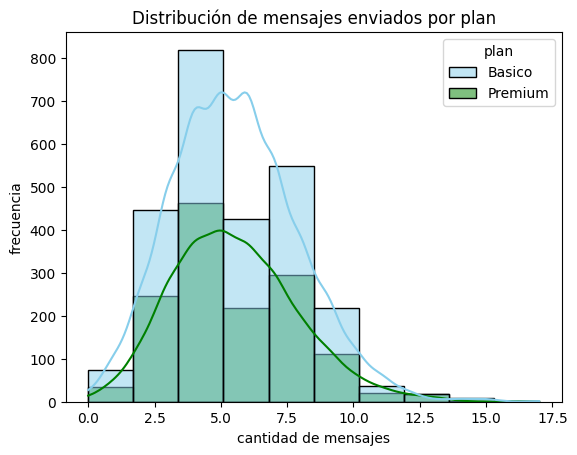

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile,x='cant_mensajes',hue='plan',bins=10,kde=True,palette=['skyblue','green'])
plt.title('Distribución de mensajes enviados por plan')
plt.xlabel('cantidad de mensajes')
plt.ylabel('frecuencia')
plt.show()

💡Insights:
- Dentro del plan premium la mayotia manda en promedio 5 mensajes y se observa una distribucion simetrica

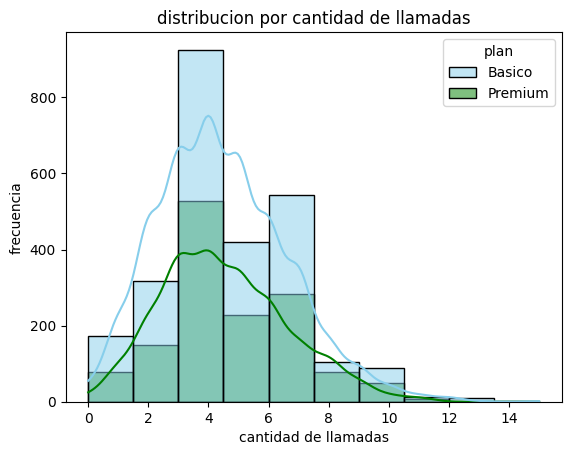

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile,x='cant_llamadas',hue='plan',bins=10,kde=True,palette=['skyblue','green'])
plt.title('distribucion por cantidad de llamadas')
plt.xlabel('cantidad de llamadas')
plt.ylabel('frecuencia')
plt.show()

💡Insights:Ambos planes hacen alrededor de 4 llamadas por cliente; no hay diferencia entre planes. La distribución es ligeramente sesgada a la derecha


In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile,x='cant_minutos_llamada',hue='plan',bins=20,kde=True,palette=['skyblue','green'])
plt.title('distribucion por duracion de llamada')
plt.xlabel('duracion de la llamada')
plt.ylabel('frecuencia')

Text(0, 0.5, 'frecuencia')

💡Insights: Sesgo a la derecha por pocos clientes con llamadas largas, presentes en ambos planes.
- ...

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for cols in columnas_numericas:
    sns.boxplot(data=user_profile[cols])
    plt.title(f'boxplot:{cols}')
    plt.show()

💡Insights:
- Age: no presenta outliers
- cant_mensajes:presenta algunos outliers normales del negocio
- cant_llamadas: presenta algunos outliers normales del negocio
- cant_minutos_llamada: presenta algunos outliers que pueden ser conferencias que usan los de plan premiium

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes','cant_llamadas','cant_minutos_llamada']
for col in columnas_limites:
    q1= user_profile[col].quantile(.25)
    q3= user_profile[col].quantile(.75)
    IQR=q3 - q1
    lower=q1-1.5*IQR
    upper=q3+1.5*IQR
    print(f'columna:{col},Q1:{q1},Q3:{q3},IQR:{IQR},lower{lower},upper{upper}')


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

💡Insights:
- cant_mensajes: mantener o no outliers, porqué? se mantienen por que la media y mediana so casi iguales asi que estos outliers no nos provocan un sezgo.
- cant_llamadas: mantener o no outliers, porqué?se mantienen, es el mismo caso que con los mensajes ademas de ser unos alores muy posibles .
- cant_minutos_llamada: mantener o no outliers, porqué? se matienen ya que aunque se ve mas dispersion son duraciones de llamadas posibles en segmentos de clientes premium, habira que hacer otra segmentacion para ver si son empresas.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
def segmentacion(fila):
    if fila['cant_llamadas']<5 and fila['cant_mensajes']<5:
        return 'Bajo uso'
    elif fila['cant_llamadas']<10 and fila['cant_mensajes']<10:
        return 'Uso medio'
    else:
        return 'Alto uso'
user_profile['grupo_uso']= user_profile.apply(segmentacion,axis=1)

In [ ]:
# verificar cambios
user_profile.head()

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
def grupo_edad(fila):
    if fila['age']<30:
        return 'Joven'
    elif fila['age']<60:
        return 'Adulto'
    else:
        return 'Adulto mayor'
user_profile['grupo_edad']=user_profile.apply(grupo_edad,axis=1)

In [ ]:
# verificar cambios
user_profile.head()

### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(user_profile['grupo_uso'])
plt.title('segmentación por uso')
plt.xlabel('Rango de uso')
plt.ylabel('Cantidad de mensajes o llamadas')
plt.show()

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(user_profile['grupo_edad'])
plt.title('segmentación por edad')
plt.xlabel('segmento de clientes')
plt.ylabel('cantidad de clientes')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
-Edad (age): 55 registros (1.4%) con el valor centinela -999. Bajaban la edad promedio de 48 a 34 años. Se reemplazaron por la mediana (47 años).
-Ciudad (city): 469 nulos + 96 registros con "?" = 565 clientes sin ciudad (14.1%). Se dejaron como nulos (pd.NA).
-Fecha de registro (reg_date): 40 registros (1%) con fecha futura (2026), imposible para datos hasta 2024. Se marcaron como nulos.
-Fecha de uso (date): 50 registros sin fecha (0.13%). El impacto es mínimo.
-Duration (55.2% nulos) y length (44.7% nulos): son nulos estructurales (MAR), no errores. Los mensajes no tienen duración y las llamadas no tienen longitud.
-churn_date (88.4% nulos): el nulo significa cliente activo. 466 clientes (11.7%) cancelaron.


🔍 **Segmentos por Edad**
-Adultos (30–59): 50.4%, Adultos mayores (60+): 30.6%, Jóvenes (<30): 19.0%. La base es mayoritariamente adulta.
-El consumo es prácticamente idéntico entre edades: ~5.5 mensajes, ~4.5 llamadas y ~23–24 minutos por cliente en cada grupo.
-La proporción de Premium también es igual en todas las edades (34–36%). La edad no explica ni cuánto se consume ni qué plan se elige.


📊 **Segmentos por Nivel de Uso**
-Uso medio: 73.6%, Bajo uso: 19.4%, Alto uso: 7.0%.
-El plan tampoco cambia con el nivel de uso: los clientes de alto uso son 33% Premium y los de bajo uso 34%. Los heavy users no están migrando a Premium, y muchos clientes de bajo uso pagan Premium.
-Outliers: hay clientes con hasta 17 mensajes, 15 llamadas y 156 minutos, por encima de los límites IQR (11.5 mensajes, 10.5 llamadas, 62 minutos). Son consumos realistas y se conservaron. Están en ambos planes, no solo en Premium.
-El consumo anual típico (5 mensajes, 4 llamadas, ~20 min) está muy por debajo de lo que incluye incluso el plan Básico (100 min y 100 mensajes al mes).


➡️ Esto sugiere que los planes actuales no están alineados con el comportamiento real de los clientes. Premium cuesta más del doble ($25 vs $12), pero sus clientes consumen igual que los de Básico, así que más de un tercio de la base (35%) paga por capacidad que no usa. Hoy Premium es el segmento más valioso en ingreso, pero también el de mayor riesgo de cancelación si el cliente percibe que paga de más. Por otro lado, el segmento más valioso por potencial es el 7% de alto uso, que hoy mayormente está en Básico.


💡 **Recomendaciones**
-Redefinir el valor del Premium con beneficios que sí se usen (más GB, apps incluidas, roaming) en lugar de más minutos y SMS, que casi no se consumen.
-Crear un plan de entrada más barato (por ejemplo, ~$8 con 50 min y 50 mensajes) para el 19% de bajo uso. Retiene al cliente que siente que le sobra el plan.
-Campaña de upgrade dirigida al 7% de alto uso en plan Básico, con una oferta tipo "llamadas ilimitadas" o un paquete empresarial.
-No segmentar la oferta por edad: los datos no muestran diferencias de consumo entre grupos, así que es mejor segmentar por uso real.
-Analizar el churn por plan y nivel de uso (466 cancelaciones) para confirmar si los Premium de bajo uso son los que más cancelan.
-Mejorar la captura de datos: ciudad obligatoria (14% faltante), validación de edad y fechas, y registrar el consumo de datos (GB), que hoy no se mide y probablemente es lo que más pesa en la elección de plan.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`